# 01 — Thu thập và khám phá dữ liệu (Steam games)

## 1. Data collection

- **Subject:** Dữ liệu nhóm sử dụng là metadata của các ứng dụng trên cửa hàng Steam. Mỗi dòng là một ứng dụng (game, DLC, nhạc, mod, phần cứng) gồm: `Appid`, tên, phân loại (`Type`), ngày phát hành, thể loại (`Genre`), nhà phát triển (`developer`), nhà phát hành (`publisher`), mô tả, giá (USD), tag do người dùng gắn, thumbnail URL, số review tích cực/tiêu cực, `ReviewScore` (Steam tính theo thang đo 0-9), yêu cầu hệ thống (OS, RAM, CPU ở dạng chuỗi tự do) và `Rank`. File thô (`SteamGames.csv`) có 29.931 dòng × 18 cột (29.789 Appid duy nhất), trải dài từ năm 1997 đến 2026. Dữ liệu đại diện cho thị trường game số trên PC và cho phép phân tích mức độ đón nhận (review), định giá, cấu hình yêu cầu và mô hình phát hành.

- **Source:**

  - Nền tảng gốc: [Steam Store](https://store.steampowered.com/)

  - Bộ dữ liệu: "Steam Game Clean" trên Kaggle, chủ sở hữu New Nguyễn (newnguyn), tác giả Le Thi Ha Phuong.

  - URL: [https://www.kaggle.com/datasets/newnguyn/steam-game-clean](https://www.kaggle.com/datasets/newnguyn/steam-game-clean)

  - Mã nguồn crawler và notebook tiền xử lý: repo GitHub ["UIT-Entropy/DS108"](https://github.com/UIT-Entropy/DS108)

  - Ngày công bố: 25/05/2026. Phiên bản cập nhật gần nhất: 13/06/2026.

  - Nhóm dùng `SteamGames.csv` (file thô). Bộ dữ liệu còn có `SteamGames_cleaned.csv` nhưng nhóm không dùng.

- **License:** MIT License. Nhóm trích dẫn bộ dữ liệu theo dạng (tác giả, tiêu đề, URL Kaggle, năm). Nội dung gốc như mô tả game và ảnh thumbnail thuộc về nhà phát triển và Valve, nên nhóm chỉ dùng cho mục đích học tập và không phân phối lại ảnh hay mô tả.

- **Collection method:**
  - **Cách thu thập (theo tác giả):** crawler Python tự viết (1) lấy danh sách App ID từ các trang kết quả tìm kiếm của Steam, (2) lấy metadata từ endpoint chi tiết app, (3) lấy tổng hợp review từ endpoint review, (4) phân tích trang app để lấy tag và yêu cầu hệ thống. Môi trường cào mặc định: Ngôn ngữ tiếng Anh, Store Region: US.

  - **Quần thể:** các ứng dụng xuất hiện trong kết quả tìm kiếm của Steam, khoảng 29,9 nghìn dòng, nhỏ hơn nhiều so với toàn bộ danh mục Steam. Quy tắc chọn mẫu (thứ tự sắp xếp, bộ lọc, giới hạn số lượng) chưa được mô tả: TODO kiểm tra trong repo.

  - **Mốc thời gian:** Kaggle metadata ghi phạm vi từ 05/02/2026–05/03/2026, nhưng thực tế dữ liệu chứa các bản ghi có review phát hành cuối tháng 05/2026.

  - **Hạn chế và sai lệch dữ liệu:**

    1. **Dữ liệu được thu thập qua nhiều phiên cào khác nhau.** Các game phát hành 18/05/2026 (Forza Horizon 6, khoảng 77 nghìn review) và 29/05/2026 (LEGO Batman: Legacy of the Dark Knight, khoảng 11 nghìn review) đã có lượng lớn review. Do đó, để tính biến tuổi game, nhóm chọn mốc thời gian cào là 13/06/2026.

    2. **Cột `Rank` không so sánh được giữa các phiên cào.** `Rank` chạy 1–13.211 rồi quay lại 1–16.719 ở dòng 13.213. Đây là do ghép nối hai phiên cào độc lập (phiên bản tháng 5 và bản cập nhật tháng 6) vào cùng một file `SteamGames.csv`. Cột `Rank` không có giá trị thứ tự toàn cục, do đó nhóm không dùng `Rank` làm biến phân tích.

    3. **Trộn lẫn nhiều loại app:** theo `Type`, khoảng 76% là game, còn lại chủ yếu là DLC (6.586) và nhạc (600). Nhóm lọc `Type == 'game'` cho các bài toán phân tích.

    4. **Dữ liệu chỉ là một lát cắt thời gian.** Dữ liệu chỉ phản ánh tổng tích lũy tại thời điểm cào. Game mới phát hành ít review hơn một phần vì chưa có đủ thời gian. `ReviewScore = 0` có nghĩa là có dưới 10 review (chưa đủ mẫu), không phải là điểm tệ.

    5. **Giá (`price`) là giá tại thời điểm cào, không phải giá gốc hay giá ra mắt.** Crawler lấy trường `final` của `price_overview` (giá sau giảm, USD, chia 100) và không lưu `initial` hay `discount_percent`. Giá bằng 0 được gán khi Steam không trả về `price_overview`, nên `price = 0` gồm game free-to-play (khoảng 82% game giá 0 có genre "Free To Play), bản demo/prologue miễn phí và có thể cả app không có giá tại cửa hàng US.

    6. **Tồn tại thiên lệch:** dữ liệu lấy từ cửa hàng hiện tại nên game đã bị gỡ khỏi cửa hàng có thể không có mặt.

    7. **Thiên lệch địa lý:** toàn bộ thông số giá và hiển thị bị ràng buộc bởi IP/Store US.

    8. **Tag do người dùng gắn sau khi phát hành**, không phản ánh trạng thái ban đầu của sản phẩm. Cần loại bỏ khỏi tập đặc trưng trong các mô hình dự đoán (ML) giai đoạn tiền phát hành.

- **Motivation:**

  - Dữ liệu thật, có dung lượng đủ lớn (khoảng 30 nghìn dòng) và đa dạng kiểu biến: số, chuỗi thời gian, văn bản, phân loại đa nhãn (`genres`, `tags`) và chuỗi tự do cần trích xuất (RAM, CPU).

  - Đáp ứng đủ cho 5 câu hỏi thống kê suy luận và 1 bài toán mô hình hóa học máy.

- **Related public notebooks:** 

  | Notebook | Tác giả | Nội dung chính | Khác với câu hỏi của nhóm thế nào |
  |---|---|---|---|
  | `02_Cleaning_data_and_imputation` | New Nguyễn | Triển khai pipeline làm sạch cơ bản: xử lý missing value, chuẩn hóa text cấu hình (RAM, CPU) và dùng LLM chuẩn hóa tag. | Tập trung vào kỹ thuật data processing/imputation chuẩn bị dataset; nhóm tập trung vào phân tích thống kê và kiểm định giả thuyết. |
  |`Steam Games Market Analysis & df - First Release` | Dat Nguyen | Thống kê mô tả (df), trực quan hóa phân bố điểm số, giá bán và các thể loại game phổ biến. | Chủ yếu dừng ở thống kê mô tả bề mặt (univariate/bivariate df); nhóm thực hiện suy luận nhân quả và kiểm soát biến gây nhiễu (confounding variables). |
  |`03_exploratory_data_analysis` | New Nguyễn | Khám phá tương quan giữa các chiều dữ liệu: phân phối giá, tỷ lệ review tích cực, các tag/thể loại phổ biến. | Mang tính mô tả tổng quan (descriptive df); nhóm thiết kế mô hình giải quyết bài toán suy luận chuyên sâu: tách hiệu ứng quy mô khỏi hiệu ứng thời gian (Q3), hiệu chỉnh đa giả thuyết (Q4), và mô hình fixed effects theo nhà phát triển (Q5). |

## 2. Data exploration
### 2.1 Nạp dữ liệu

In [1]:
import os

print(f"Thư mục hiện tại: {os.getcwd()}")
print(f"Các file/folder tại đây: {os.listdir()}")

Thư mục hiện tại: /home/thanhthuy/KHDL/NaN_FINALPROJECT_DATASCIENCE/notebooks
Các file/folder tại đây: ['02_analysis_q3.ipynb', 'README.md', '03_ml_q5.ipynb', 'test.ipynb', '02_analysis_q4.ipynb', 'note.ipynb', '02_analysis_q1.ipynb', '02_analysis_q2.ipynb', '01_overview.ipynb', '03_ml_q6.ipynb', '01_collection_exploration_loi.ipynb', '01_collection_exploration.ipynb', '00_questioning.ipynb', 'preprocessing_experiments']


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

CRAWL_DATE = pd.Timestamp("2026-06-13")   # mốc thời gian cào đã chọn của nhóm
MIN_YEAR = 1997
RAW_PATH = "../data/raw/SteamGames.csv"
df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()

### 2.2. Overview

In [3]:
# ==============================================================================
# 1. OVERVIEW, DATA DICTIONARY & DUPLICATES
# ==============================================================================
print(f"Kích thước gốc: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"Số dòng hoàn toàn rỗng: {df.isna().all(axis=1).sum()}")

# Bảng tổng quan thông tin thuộc tính
overview_table = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
display(overview_table)
print(f"Bộ nhớ tiêu thụ: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB\n")

print(f"\nXem trước 5 dòng đầu")
display(df.head(5))

# Phiên cào: Rank bị reset khi nối nhiều phiên
reset_idx = df.index[df["Rank"].diff() < 0].tolist()
df["crawl_block"] = (df["Rank"].diff() < 0).cumsum()
print(f"Số phiên cào (crawl_block): {df['crawl_block'].nunique()} | Rank reset tại dòng: "f"{[f'{i + 1:,}' for i in reset_idx]}")

n_dup_full = df.duplicated().sum()
n_dup_no_rank = df.drop(columns=["Rank", "crawl_block"]).duplicated().sum()
n_dup_appid = df.duplicated(subset=["Appid"]).sum()

print(f"Trùng cả dòng (gồm Rank): {n_dup_full} | Trùng nếu bỏ Rank: {n_dup_no_rank} | Trùng Appid: {n_dup_appid}")

dup_rows = df[df.duplicated(subset=["Appid"], keep=False)]
chk_dup = dup_rows.groupby("Appid").agg(
    n_blocks=("crawl_block", "nunique"),
    n_pos=("PositiveReview", "nunique"),
    n_neg=("NegativeReview", "nunique"),
    n_price=("price", "nunique"),
)
n_ids = len(chk_dup)
n_cross = int((chk_dup["n_blocks"] > 1).sum())
n_diff_rev = int(((chk_dup["n_pos"] > 1) | (chk_dup["n_neg"] > 1)).sum())
n_diff_price = int((chk_dup["n_price"] > 1).sum())
print(f"{n_ids} Appid bị trùng | nằm ở nhiều phiên cào: {n_cross} | lệch số review: {n_diff_rev} | lệch giá: {n_diff_price}")

# Quy tắc bỏ trùng: Giữ dòng có tổng số review lớn hơn (cập nhật mới hơn)
df["total_reviews"] = df["PositiveReview"] + df["NegativeReview"]
df = (
    df.sort_values(["Appid", "total_reviews"], ascending=[True, False])
    .drop_duplicates("Appid", keep="first")
    .sort_index()
)
print(f"Sau khi khử trùng Appid: {len(df):,} dòng ({df['Appid'].nunique():,} Appid duy nhất)\n")

Kích thước gốc: 29,931 dòng × 18 cột
Số dòng hoàn toàn rỗng: 0


,dtype,n_missing,pct_missing,n_unique
Appid,int64,0,0.00,29789
Name,str,0,0.00,29779
Type,str,0,0.00,6
ReleaseDate,str,14,0.05,4416
Genres,str,413,1.38,1185
Developers,str,26,0.09,14777
Publishers,str,1045,3.49,11238
Description,str,52,0.17,29651
price,str,0,0.00,452
Thumbnail,str,0,0.00,29786


Bộ nhớ tiêu thụ: 114.5 MB


Xem trước 5 dòng đầu


,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,Description,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,OsRequirement,MemoryRequirement,CpuRequirement,Rank
0,3764200,Resident Evil Requiem,game,"Feb 26, 2026","Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",Resident Evil Requiem Deluxe Edition Resident ...,69.99$,https://shared.akamai.steamstatic.com/store_it...,NaN,9,23715,793,NaN,NaN,NaN,1
1,730,Counter-Strike 2,game,"Aug 21, 2012","Action,Free To Play",Valve,Valve,"For over two decades, Counter-Strike has offer...",0$,https://shared.akamai.steamstatic.com/store_it...,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393,Windows® 10,8 GB RAM,4 hardware CPU threads - Intel® Core™ i5 750 o...,2
2,1808500,ARC Raiders,game,"Oct 30, 2025",Action,Embark Studios,Embark Studios,ARC Raiders Deluxe Edition ARC Raiders Deluxe ...,39.99$,https://shared.akamai.steamstatic.com/store_it...,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194,Windows 10 or later 64-bit (latest update),12 GB RAM,Intel Core i5-6600K or AMD Ryzen R5 1600 proce...,3
3,359550,Tom Clancy's Rainbow Six Siege,game,"Dec 1, 2015","Action,Free To Play",Ubisoft Montreal,Ubisoft,Season 11 Year 1 Overview Year 11 Roadmap Free...,0$,https://shared.akamai.steamstatic.com/store_it...,NaN,8,522886,106839,NaN,NaN,NaN,4
4,1172470,Apex Legends™,game,"Nov 4, 2020","Action,Adventure,Free To Play",Respawn,Electronic Arts,Apex Legends: Breach About the Game Conquer wi...,0$,https://shared.akamai.steamstatic.com/store_it...,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216,64-bit Windows 10,6 GB RAM,"AMD FX 4350 or Equivalent, Intel Core i3 6300 ...",5


Số phiên cào (crawl_block): 2 | Rank reset tại dòng: ['13,213']
Trùng cả dòng (gồm Rank): 0 | Trùng nếu bỏ Rank: 141 | Trùng Appid: 142
142 Appid bị trùng | nằm ở nhiều phiên cào: 0 | lệch số review: 1 | lệch giá: 0
Sau khi khử trùng Appid: 29,789 dòng (29,789 Appid duy nhất)



**Ý nghĩa của mỗi dòng**

| Cột | Ý nghĩa | Giữ/bỏ/chuyển đổi |
|---|---|---|
| Appid | Mã định danh ứng dụng trên Steam | Giữ (Khóa chính, dùng để khử trùng) |
| Name | Tên ứng dụng | Giữ (Tham chiếu định danh) |
| Type | Phân loại (game, dlc, music, ...) | Lọc giữ Type == 'game' cho phân tích chính |
| ReleaseDate | Ngày phát hành (chuỗi 'Mon DD, YYYY') | Chuyển sang datetime, trích xuất year |
| Generes | Danh sách thể loại / cờ phân loại | Chuẩn hóa, tách cờ hệ thống & gom nhóm hiếm |
| Developers | Đơn vị phát triển | Chuẩn hóa chuỗi (lowercase, bỏ Inc/Ltd) |
| Publishers | Đơn vị phát hành | Chuẩn hóa chuỗi, đối chiếu tạo biến self_published |
| Description | Mô tả ngắn sản phẩm | Chỉ trích xuất độ dài văn bản (nếu cần), không đưa thô vào ML |
| price | Giá hiển thị tại thời điểm cào | Chuyển sang float (price_num), phân nhóm price_tier |
| Thumbnails | URL ảnh đại diện | Bỏ (Không phục vụ phân tích thống kê/ML) |
| Tags | Nhãn do người dùng gắn sau phát hành | Giữ cho EDA; Loại khỏi mô hình dự đoán (tránh Data Leakage) |
| ReviewScore | Điểm tổng hợp của Steam (0–9) | Bỏ khỏi ma trận tương quan/ML (suy diễn trực tiếp từ review) |
| PositiveReview | Số lượt đánh giá tích cực | Giữ, dùng tính total_reviews và pos_rate |
| NegativeReview | Số lượt đánh giá tiêu cực | Giữ, dùng tính total_reviews và pos_rate |
| OsRequirement | Hệ điều hành yêu cầu (chuỗi tự do) | Bóc tách cờ hỗ trợ Windows/macOS/Linux |
| MemoryRequirement | Dung lượng RAM yêu cầu (chuỗi tự do) | Bóc tách regex sang GB (ram_gb) để tạo hw_index |
| CpuRequirement | Vi xử lý yêu cầu (chuỗi tự do) | Bóc tách xung nhịp GHz & dòng chip (i3/i5/i7/i9) tạo hw_index |
| Rank | Thứ tự thu thập trong phiên cào | Bỏ (Bị reset do nối nhiều phiên cào) |

### 2.3. Tiền biến đổi phục vụ df


Các giá trị ReleaseDate không parse được theo định dạng '%b %d, %Y' (ví dụ: 'Jan 01, 2020'):
{nan: 14, 'April 2026': 1}
Tổng: 15 dòng | ngày > mốc cào 2026-06-13: 2 | ngày < 1997: 0


/tmp/ipykernel_3954/236158687.py:17: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ct_year.rename(index={last_year: f"{last_year}* (partial)"}, inplace=True)


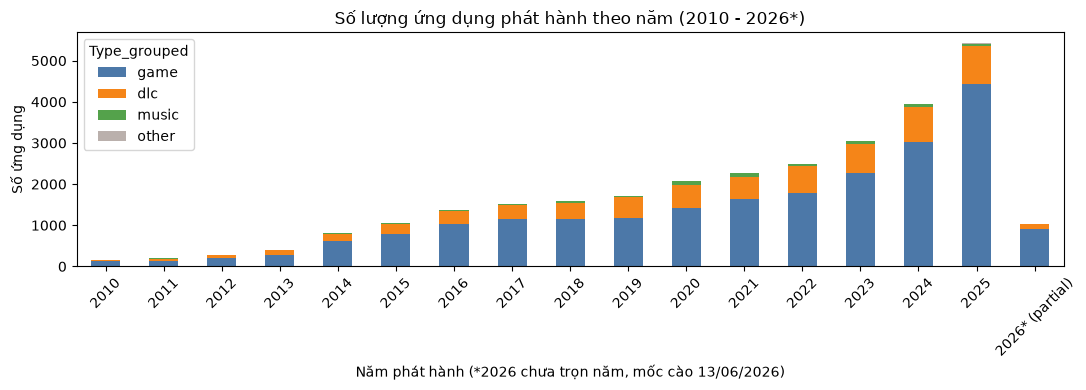

price không parse được (NaN): 0 | giá âm: 0
Tỷ lệ game có giá = 0: 6.1%
-> Trong số game giá = 0, 82.2% có genre 'Free To Play' (phần còn lại: demo, thiếu price_overview...).
Số dòng vi phạm quy ước 'ReviewScore == 0 <=> total_reviews < 10': 0



In [4]:
# ==============================================================================
# 2. TIỀN BIẾN ĐỔI PHỤC VỤ df: NGÀY PHÁT HÀNH, GIÁ, REVIEW
# ==============================================================================
df["release_dt"] = pd.to_datetime(df["ReleaseDate"], format="%b %d, %Y", errors="coerce")
df["year"] = df["release_dt"].dt.year
unparsed_dates = df.loc[df["release_dt"].isna(), "ReleaseDate"].value_counts(dropna=False)
print(f"\nCác giá trị ReleaseDate không parse được theo định dạng '%b %d, %Y' (ví dụ: 'Jan 01, 2020'):")
print(unparsed_dates.to_dict())
print(f"Tổng: {df['release_dt'].isna().sum()} dòng | ngày > mốc cào {CRAWL_DATE.date()}: "
      f"{(df['release_dt'] > CRAWL_DATE).sum()} | ngày < {MIN_YEAR}: {(df['release_dt'].dt.year < MIN_YEAR).sum()}")

# Biểu đồ số app theo năm và Type
df["Type_grouped"] = df["Type"].where(df["Type"].isin(["game", "dlc", "music"]), "other")
ct_year = pd.crosstab(df.loc[df["year"] >= 2010, "year"].astype(int), df["Type_grouped"])
ct_year = ct_year.reindex(columns=["game", "dlc", "music", "other"], fill_value=0)
last_year = int(ct_year.index.max())
ct_year.rename(index={last_year: f"{last_year}* (partial)"}, inplace=True)

ax = ct_year.plot(kind="bar", stacked=True, figsize=(11, 4), color=["#4c78a8", "#f58518", "#54a24b", "#bab0ac"])
ax.set_title(f"Số lượng ứng dụng phát hành theo năm (2010 - {last_year}*)")
ax.set_xlabel(f"Năm phát hành (*{last_year} chưa trọn năm, mốc cào {CRAWL_DATE:%d/%m/%Y})")
ax.set_ylabel("Số ứng dụng")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Giá
df["price_num"] = (
    df["price"].astype(str).str.replace("$", "", regex=False).str.strip()
    .replace({"Free": "0", "Free to Play": "0"})
)
df["price_num"] = pd.to_numeric(df["price_num"], errors="coerce")
print(f"price không parse được (NaN): {df['price_num'].isna().sum()} | giá âm: {(df['price_num'] < 0).sum()}")

games_zero_price = df[(df["Type"] == "game") & (df["price_num"] == 0)]
f2p_genre_rate = games_zero_price["Genres"].fillna("").str.contains("Free To Play", case=False).mean() * 100
print(f"Tỷ lệ game có giá = 0: {(df.loc[df['Type'] == 'game', 'price_num'] == 0).mean() * 100:.1f}%")
print(f"-> Trong số game giá = 0, {f2p_genre_rate:.1f}% có genre 'Free To Play' (phần còn lại: demo, thiếu price_overview...).")

# pos_rate và quy ước ReviewScore == 0
df["total_reviews"] = df["PositiveReview"] + df["NegativeReview"]
df["pos_rate"] = df["PositiveReview"] / df["total_reviews"].where(df["total_reviews"] > 0)
viol = ((df["ReviewScore"] == 0) != (df["total_reviews"] < 10)).sum()
print(f"Số dòng vi phạm quy ước 'ReviewScore == 0 <=> total_reviews < 10': {viol}\n")

### 2.4. Numerical columns & outliers

Thống kê mô tả các biến số (Type == 'game')


,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
price_num,"22,608.00",12.64,12.31,0.00,0.00,4.99,9.99,17.99,59.99,269.99,3.28
PositiveReview,"22,608.00","2,065.62","16,048.57",0.00,2.00,34.00,111.00,502.00,"37,619.81","1,214,897.00",32.72
NegativeReview,"22,608.00",292.93,"2,611.91",0.00,0.00,4.00,16.00,81.00,"4,480.51","202,393.00",38.55
total_reviews,"22,608.00","2,358.55","18,093.23",0.00,2.00,39.00,131.00,602.00,"42,890.28","1,417,290.00",34.13
pos_rate,"22,606.00",0.85,0.12,0.00,0.45,0.80,0.88,0.94,1.00,1.00,-1.62



Kiểm tra tính hợp lý min/max & giá trị placeholder


,min,max,n_negative,n_zero,n_na
price_num,0.00,269.99,0,1377,0
PositiveReview,0.00,"1,214,897.00",0,32,0
NegativeReview,0.00,"202,393.00",0,1708,0
total_reviews,0.00,"1,417,290.00",0,2,0
pos_rate,0.00,1.00,0,30,2


Giá trị nghi placeholder trong price_num: {-1: 0, 999: 0, 9999: 0, 99999: 0}
Giá trị nghi placeholder trong total_reviews: {-1: 0, 999: 3, 9999: 0, 99999: 0}
pos_rate ngoài [0,1]: 0 | game không có review nào: 2 (0.0%) | game < 10 review: 1,274 (5.6%)


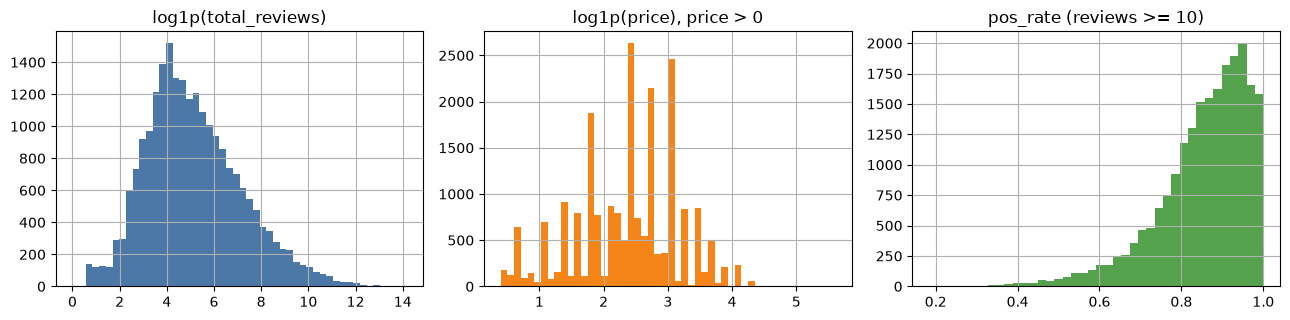

Outliers [price > 0    ] -> IQR(raw): 2.8% | IQR(log1p): 0.0% | |z|>3 (log1p): 0.1%
Outliers [total_reviews] -> IQR(raw): 15.2% | IQR(log1p): 1.2% | |z|>3 (log1p): 0.5%

Top 5 giá cao nhất/nhiều review nhất:


,Name,Type,price_num,total_reviews
1444,Valve Index® Headset,hardware,499.00,0
456,Steam Deck,hardware,399.00,17
15180,Clickteam Fusion 2.5 Developer Upgrade,dlc,299.99,16
482,Valve Index® Controllers,hardware,279.00,0
6845,Houdini Indie,game,269.99,138


,Name,Type,price_num,total_reviews
1,Counter-Strike 2,game,0.00,1417290
3,Tom Clancy's Rainbow Six Siege,game,0.00,629725
9,HELLDIVERS™ 2,game,39.99,609378
113,Terraria,game,9.99,585013
204,Garry's Mod,game,9.99,521058


-> Giá cao nhất: Valve Index® Headset ($499, Type=hardware)
-> Nhiều review nhất: Counter-Strike 2 (1,417,290 reviews).


In [5]:
# ==============================================================================
# 3. NUMERICAL COLUMNS & OUTLIERS
# ==============================================================================
num_cols = ["price_num", "PositiveReview", "NegativeReview", "total_reviews", "pos_rate"]
g_all = df[df["Type"] == "game"]

print("Thống kê mô tả các biến số (Type == 'game')")
desc = g_all[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["skew"] = g_all[num_cols].skew()
display(desc)

print("\nKiểm tra tính hợp lý min/max & giá trị placeholder")
plaus = pd.DataFrame({
    "min": g_all[num_cols].min(),
    "max": g_all[num_cols].max(),
    "n_negative": (g_all[num_cols] < 0).sum(),
    "n_zero": (g_all[num_cols] == 0).sum(),
    "n_na": g_all[num_cols].isna().sum(),
})
display(plaus)
sentinels = [-1, 999, 9999, 99999]
for c in ["price_num", "total_reviews"]:
    print(f"Giá trị nghi placeholder trong {c}:", {v: int((g_all[c] == v).sum()) for v in sentinels})
print(f"pos_rate ngoài [0,1]: {(~g_all['pos_rate'].dropna().between(0, 1)).sum()} | "
      f"game không có review nào: {(g_all['total_reviews'] == 0).sum():,} "
      f"({(g_all['total_reviews'] == 0).mean() * 100:.1f}%) | game < 10 review: "
      f"{(g_all['total_reviews'] < 10).sum():,} ({(g_all['total_reviews'] < 10).mean() * 100:.1f}%)")

# Hình dạng phân phối
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
np.log1p(g_all["total_reviews"]).hist(bins=50, ax=axes[0], color="#4c78a8")
axes[0].set_title("log1p(total_reviews)")
np.log1p(g_all.loc[g_all["price_num"] > 0, "price_num"]).hist(bins=50, ax=axes[1], color="#f58518")
axes[1].set_title("log1p(price), price > 0")
g_all.loc[g_all["total_reviews"] >= 10, "pos_rate"].hist(bins=40, ax=axes[2], color="#54a24b")
axes[2].set_title("pos_rate (reviews >= 10)")
plt.tight_layout()
plt.show()

# Outliers: IQR và z-score
def iqr_pct(x):
    q1, q3 = x.quantile([0.25, 0.75])
    k = q3 - q1
    return ((x < q1 - 1.5 * k) | (x > q3 + 1.5 * k)).mean() * 100

for name, s in {"price > 0": g_all.loc[g_all["price_num"] > 0, "price_num"],
                "total_reviews": g_all["total_reviews"]}.items():
    s = s.dropna()
    x = np.log1p(s)
    z = (x - x.mean()) / x.std()
    print(f"Outliers [{name:<13}] -> IQR(raw): {iqr_pct(s):.1f}% | IQR(log1p): {iqr_pct(x):.1f}% "
          f"| |z|>3 (log1p): {(z.abs() > 3).mean() * 100:.1f}%")

print("\nTop 5 giá cao nhất/nhiều review nhất:")
top_price = df.nlargest(5, "price_num")[["Name", "Type", "price_num", "total_reviews"]]
top_rev = df.nlargest(5, "total_reviews")[["Name", "Type", "price_num", "total_reviews"]]
display(top_price)
display(top_rev)
r1, r2 = top_price.iloc[0], top_rev.iloc[0]
print(f"-> Giá cao nhất: {r1['Name']} (${r1['price_num']:,.0f}, Type={r1['Type']})")
print(f"-> Nhiều review nhất: {r2['Name']} ({r2['total_reviews']:,.0f} reviews).")

### 2.5. Khám phá cấu hình phần cứng

Khám phá 3 cột cấu hình (OsRequirement, MemoryRequirement, CpuRequirement)
OsRequirement: 4,027 chuỗi khác nhau
MemoryRequirement: 399 chuỗi khác nhau
CpuRequirement: 8,430 chuỗi khác nhau

Tỷ lệ (%) chuỗi OS nhắc tới từng nền tảng: {'windows': 97.1, 'macos': 0.1, 'linux': 0.0}
Top 5 chuỗi OS: {'Windows 10': 3331, 'Windows 7': 2289, 'Windows 10 64-bit': 624, 'Windows XP': 514, 'Windows 7+': 382}

RAM parse thành công: 25,776 / 25,822 (99.82%)
Chuỗi MemoryRequirement không parse được: {'４ GB RAM': 10, '８ GB RAM': 6, '4 RAM MB RAM': 5, '4 RAM GB RAM': 5, '1+ gigs of RAM GB RAM': 4}
Phân phối ram_gb: {'count': 25776.0, 'mean': 4.57, 'std': 18.81, 'min': 0.0, '25%': 2.0, '50%': 4.0, '75%': 8.0, 'max': 2048.0}
ram_gb < 0.125 hoặc > 128 (nghi lỗi parse): 522

Tỷ lệ chuỗi CPU chứa GHz: 0.461 | chứa Core i3/i5/i7/i9: 0.457
GHz parse được: 11,953 | min/median/max: 0.00 / 2.00 / 220.00 | ngoài [0.5, 6] GHz: 77


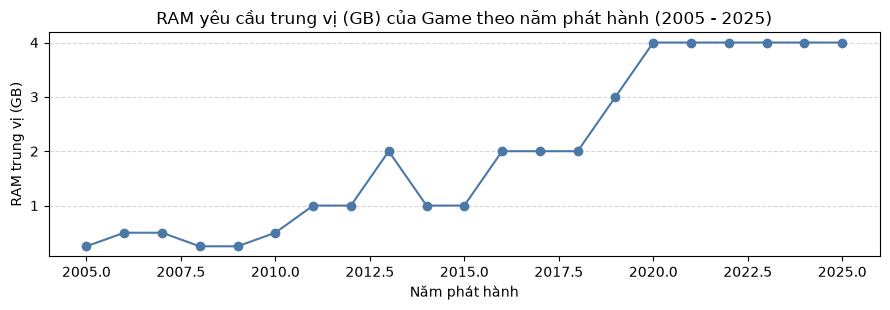

In [6]:
# ==============================================================================
# 4. KHÁM PHÁ CẤU HÌNH PHẦN CỨNG: OS, RAM, CPU
# ==============================================================================
print("Khám phá 3 cột cấu hình (OsRequirement, MemoryRequirement, CpuRequirement)")
for col in ["OsRequirement", "MemoryRequirement", "CpuRequirement"]:
    print(f"{col}: {df[col].nunique():,} chuỗi khác nhau")

# OS
os_s = df["OsRequirement"].dropna().str.lower()
os_flags = pd.DataFrame({
    "windows": os_s.str.contains("win"),
    "macos": os_s.str.contains(r"mac|os x"),
    "linux": os_s.str.contains(r"linux|ubuntu|steamos"),
})
print("\nTỷ lệ (%) chuỗi OS nhắc tới từng nền tảng:", (os_flags.mean() * 100).round(1).to_dict())
print("Top 5 chuỗi OS:", df["OsRequirement"].value_counts().head(5).to_dict())

# RAM
ram = df["MemoryRequirement"].str.extract(r"(\d+(?:\.\d+)?)\s*(GB|MB)", flags=re.I)
df["ram_gb"] = pd.to_numeric(ram[0], errors="coerce") / ram[1].str.upper().map({"GB": 1, "MB": 1024})
n_ram_ok = df["ram_gb"].notna().sum()
n_ram_raw = df["MemoryRequirement"].notna().sum()
print(f"\nRAM parse thành công: {n_ram_ok:,} / {n_ram_raw:,} ({n_ram_ok / n_ram_raw * 100:.2f}%)")
print("Chuỗi MemoryRequirement không parse được:",
      df.loc[df["MemoryRequirement"].notna() & df["ram_gb"].isna(), "MemoryRequirement"].value_counts().head(5).to_dict())
print("Phân phối ram_gb:", df["ram_gb"].describe().round(2).to_dict())
print(f"ram_gb < 0.125 hoặc > 128 (nghi lỗi parse): {((df['ram_gb'] < 0.125) | (df['ram_gb'] > 128)).sum()}")

# CPU
cpu_s = df["CpuRequirement"].dropna()
ghz = pd.to_numeric(cpu_s.str.extract(r"(\d+(?:\.\d+)?)\s*ghz", flags=re.I)[0], errors="coerce")
has_ghz = cpu_s.str.contains(r"\d\s*ghz", case=False).mean()
has_core = cpu_s.str.contains(r"\bi[3579]\b", case=False).mean()
print(f"\nTỷ lệ chuỗi CPU chứa GHz: {has_ghz:.3f} | chứa Core i3/i5/i7/i9: {has_core:.3f}")
print(f"GHz parse được: {ghz.notna().sum():,} | min/median/max: {ghz.min():.2f} / {ghz.median():.2f} / {ghz.max():.2f} "
      f"| ngoài [0.5, 6] GHz: {((ghz < 0.5) | (ghz > 6)).sum()}")

ram_by_year = df[df["Type"] == "game"].groupby("year")["ram_gb"].median().loc[2005:2025]
plt.figure(figsize=(9, 3.2))
ram_by_year.plot(marker="o", color="#4c78a8")
plt.title("RAM yêu cầu trung vị (GB) của Game theo năm phát hành (2005 - 2025)")
plt.xlabel("Năm phát hành")
plt.ylabel("RAM trung vị (GB)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 2.6. Cột phân loại

In [7]:
# ==============================================================================
# 5. CỘT PHÂN LOẠI: GENRES, DEVELOPERS, PUBLISHERS & SELF-PUBLISHING
# ==============================================================================
game_mask = df["Type"] == "game"

# 5.1 Type: số giá trị, tần suất, độ cân bằng
type_counts = df["Type"].value_counts(dropna=False)
display(pd.DataFrame({"n": type_counts, "pct": type_counts / len(df) * 100}))
print(f"'{type_counts.index[0]}' chiếm {type_counts.iloc[0] / len(df) * 100:.1f}% | '{type_counts.index[-1]}' chiếm {type_counts.iloc[-1] / len(df) * 100:.1f}%")

# 5.2 Genres
genres_exp = df.loc[game_mask, "Genres"].dropna().str.split(",").explode().str.strip()
g_counts = genres_exp.value_counts()
print(f"\nTổng số Genres: {len(g_counts)} | nhãn có >= 100 game: {(g_counts >= 100).sum()} "
      f"| nhãn hiếm (< 100 game): {(g_counts < 100).sum()}")
display(g_counts.head(20).to_frame("n_games"))

store_flags = ["Free To Play", "Early Access"]
software_labels = ["Utilities", "Design & Illustration", "Animation & Modeling", "Accounting",
                   "Photo Editing", "Video Production", "Web Publishing", "Audio Production", "Software Training"]
content_labels = ["Violent", "Gore", "Nudity", "Sexual Content"]
for title, names in [("Cờ cửa hàng", store_flags), ("Nhãn phần mềm", software_labels), ("Nhãn cảnh báo nội dung", content_labels)]:
    print(f"{title}:", g_counts.reindex(names).fillna(0).astype(int).to_dict())

# 5.3 Developers & Publishers: chuẩn hóa nhãn
def clean_company_name(s):
    s = s.astype("string").str.strip().str.lower()
    s = s.str.replace(r"[^\w\s]", " ", regex=True)
    s = s.str.replace(r"\b(inc|ltd|llc|co|corp|corporation|limited|gmbh)\b", " ", regex=True)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s.mask(s == "")

def same_company(dev, pub):
    d, p = clean_company_name(dev), clean_company_name(pub)
    res = (d == p).astype("boolean")
    res[d.isna() | p.isna()] = pd.NA
    return res

def spelling_variants(series, top=5):
    s = series.dropna()
    tmp = pd.DataFrame({"raw": s, "clean": clean_company_name(s)}).dropna()
    var = tmp.groupby("clean")["raw"].nunique().sort_values(ascending=False)
    return {k: sorted(tmp.loc[tmp["clean"] == k, "raw"].unique())[:4] for k in var[var > 1].head(top).index}

for col in ["Developers", "Publishers"]:
    s_valid = df[col].dropna()
    n_raw = s_valid.nunique()
    n_lower = s_valid.str.strip().str.lower().nunique()
    n_clean = clean_company_name(s_valid).nunique()
    n_multi = df.loc[game_mask, col].dropna().str.contains(",").mean() * 100
    print(f"\n{col:<10}: gốc = {n_raw:,} | strip+lower = {n_lower:,} | bỏ hậu tố = {n_clean:,} "
          f"| game có nhiều tên (dấu phẩy): {n_multi:.1f}%")
    top = df.loc[game_mask, col].value_counts().head(10)
    display(pd.DataFrame({"n_games": top, "pct_games": top / game_mask.sum() * 100}))
    print(f"Ví dụ cùng một công ty, nhiều cách viết ({col}):", spelling_variants(df.loc[game_mask, col]))

# 5.4 Tỷ lệ tự phát hành (3 định nghĩa)
valid_dp = df[game_mask & df["Developers"].notna() & df["Publishers"].notna()].copy()
rate_exact = (valid_dp["Developers"] == valid_dp["Publishers"]).mean() * 100
rate_lower = (valid_dp["Developers"].str.strip().str.lower() == valid_dp["Publishers"].str.strip().str.lower()).mean() * 100
rate_norm = same_company(valid_dp["Developers"], valid_dp["Publishers"]).mean() * 100
print(f"\nTỷ lệ Self-Published (Game): chính xác = {rate_exact:.1f}% | lower+strip = {rate_lower:.1f}% "
      f"| chuẩn hóa hậu tố = {rate_norm:.1f}%")

# 5.5 Tags
tags_exp = df.loc[game_mask, "Tags"].dropna().str.split(",").explode().str.strip()
n_tag_per_game = df.loc[game_mask, "Tags"].dropna().str.split(",").str.len()
print(f"\nTags: {tags_exp.nunique():,} nhãn khác nhau | trung bình {n_tag_per_game.mean():.1f} tag/game")
display(tags_exp.value_counts().head(15).to_frame("n_games"))

,n,pct
Type,,
game,22608,75.89
dlc,6557,22.01
music,595,2.00
mod,23,0.08
hardware,5,0.02
video,1,0.00


'game' chiếm 75.9% | 'video' chiếm 0.0%

Tổng số Genres: 27 | nhãn có >= 100 game: 14 | nhãn hiếm (< 100 game): 13


,n_games
Genres,
Indie,14591
Adventure,9694
Action,9074
Casual,7656
Simulation,5755
RPG,4978
Strategy,4897
Early Access,1758
Free To Play,1184


Cờ cửa hàng: {'Free To Play': 1184, 'Early Access': 1758}
Nhãn phần mềm: {'Utilities': 168, 'Design & Illustration': 120, 'Animation & Modeling': 97, 'Accounting': 1, 'Photo Editing': 38, 'Video Production': 49, 'Web Publishing': 28, 'Audio Production': 38, 'Software Training': 28}
Nhãn cảnh báo nội dung: {'Violent': 23, 'Gore': 9, 'Nudity': 8, 'Sexual Content': 7}

Developers: gốc = 14,777 | strip+lower = 14,693 | bỏ hậu tố = 14,602 | game có nhiều tên (dấu phẩy): 12.2%


,n_games,pct_games
Developers,,
"KOEI TECMO GAMES CO., LTD.",62,0.27
"Kairosoft Co.,Ltd",51,0.23
Square Enix,48,0.21
Choice of Games,46,0.20
"CAPCOM Co., Ltd.",44,0.19
Milestone S.r.l.,37,0.16
Winged Cloud,37,0.16
Hosted Games,36,0.16
"100 Cozy Games,Cats",36,0.16


Ví dụ cùng một công ty, nhiều cách viết (Developers): {'capcom': ['CAPCOM CO., LTD', 'CAPCOM CO., LTD.', 'CAPCOM Co., Ltd.', 'Capcom'], 'maxis': ['MAXIS', 'Maxis', 'Maxis™'], 'volition': ['Volition', 'Volition Inc', 'Volition Inc.'], 'cyberconnect2': ['CyberConnect2', 'CyberConnect2 Co. Ltd.', 'CyberConnect2 Co., Ltd.'], 'joycity': ['JOYCITY', 'JOYCITY Corporation', 'Joycity']}

Publishers: gốc = 11,238 | strip+lower = 11,091 | bỏ hậu tố = 11,017 | game có nhiều tên (dấu phẩy): 11.2%


,n_games,pct_games
Publishers,,
Kagura Games,172,0.76
Ubisoft,131,0.58
Square Enix,123,0.54
THQ Nordic,117,0.52
Devolver Digital,113,0.50
Sekai Project,108,0.48
Electronic Arts,102,0.45
indie.io,99,0.44
SEGA,96,0.42


Ví dụ cùng một công ty, nhiều cách viết (Publishers): {'capcom': ['CAPCOM CO., LTD', 'CAPCOM CO., LTD.', 'CAPCOM Co., Ltd.', 'CAPCOM Co., Ltd. '], 'bandai namco entertainment': ['BANDAI NAMCO Entertainment', 'BANDAI NAMCO Entertainment Inc.', 'Bandai Namco Entertainment', 'Bandai Namco Entertainment Inc.'], 'saber interactive': ['Saber Interactive', 'Saber Interactive Inc', 'Saber Interactive Inc.', 'Saber Interactive Inc. '], 'microprose software': [' MicroProse Software', 'MicroProse Software', 'MicroProse Software ', 'Microprose Software'], 'game for people': [' Game for people', ' Game for people\t', 'Game for people']}

Tỷ lệ Self-Published (Game): chính xác = 55.0% | lower+strip = 55.3% | chuẩn hóa hậu tố = 55.4%

Tags: 446 nhãn khác nhau | trung bình 17.0 tag/game


,n_games
Tags,
Singleplayer,15575
Indie,10730
Adventure,9791
Action,8829
Casual,8466
2D,7840
Simulation,6000
Atmospheric,5857
Story Rich,5589


### 2.7. Phân tích quy luật dữ liệu thiếu

In [8]:
# ==============================================================================
# 6. PHÂN TÍCH QUY LUẬT DỮ LIỆU THIẾU - MISSING DATA PATTERNS 
# ==============================================================================
# 6.1 Placeholder dạng chuỗi
PLACEHOLDERS = {"", "n/a", "na", "none", "null", "unknown", "nan", "-"}
obj_cols = [c for c in df_raw.columns if df_raw[c].dtype == "object"]
ph = {c: int(df[c].dropna().astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum()) for c in obj_cols}
print("Placeholder chuỗi (rỗng/N/A/Unknown...)")
print({k: v for k, v in ph.items() if v > 0} or "Không phát hiện")

# 6.2 Thiếu theo cột (dữ liệu gốc)
raw_cols = [c for c in df_raw.columns if c in df.columns]
miss_all = pd.DataFrame({"n_missing": df[raw_cols].isna().sum(), "pct": df[raw_cols].isna().mean() * 100})
print(f"\nSố lượng & % thiếu theo cột (sau khử trùng)")
display(miss_all[miss_all["n_missing"] > 0].sort_values("n_missing", ascending=False))

req_cols = ["OsRequirement", "MemoryRequirement", "CpuRequirement"]
miss_cols = ["Publishers", "Developers", "Genres", "Tags"] + req_cols
miss_bool = df[miss_cols].isna()

print(f"\nTỷ lệ thiếu (%) theo Type")
display(miss_bool.groupby(df["Type"]).mean().mul(100).round(1))

print(f"\nTỷ lệ thiếu (%) theo giai đoạn phát hành (Type == 'game')")
year_bins = pd.cut(df.loc[game_mask, "year"], [1996, 2009, 2014, 2019, 2022, 2026])
display(miss_bool.loc[game_mask].groupby(year_bins, observed=True).mean().mul(100).round(1))

print(f"\nThiếu đồng thời cả 3 cột cấu hình: {df[req_cols].isna().all(axis=1).mean() * 100:.1f}% "
      f"| thiếu ít nhất 1 cột cấu hình: {df[req_cols].isna().any(axis=1).mean() * 100:.1f}%")
print(f"\nPublishers thiếu toàn tập: {df['Publishers'].isna().sum()} dòng | riêng game: "
      f"{df.loc[game_mask, 'Publishers'].isna().sum()} dòng ({df.loc[game_mask, 'Publishers'].isna().mean() * 100:.1f}%)")

# 6.3 Kế hoạch xử lý (số liệu tính từ dữ liệu)
def pct_na(col, mask=None):
    s = df[col] if mask is None else df.loc[mask, col]
    return s.isna().mean() * 100

pub_by_type = df.groupby("Type")["Publishers"].apply(lambda s: s.isna().mean() * 100)
req_any = {c: pct_na(c) for c in req_cols}
req_music = df.loc[df["Type"] == "music", req_cols].isna().mean().mean() * 100
req_old = df.loc[game_mask & (df["year"] < 2010), req_cols].isna().mean().mean() * 100

missing_summary = pd.DataFrame([
    ("ReleaseDate", f"{df['release_dt'].isna().sum():,} dòng ({df['release_dt'].isna().mean() * 100:.2f}%)"),
    ("Developers", f"{df['Developers'].isna().sum():,} dòng ({pct_na('Developers'):.2f}%)"),
    ("Publishers", f"{df['Publishers'].isna().sum():,} dòng ({pct_na('Publishers'):.2f}%)"),
    ("Genres", f"{df['Genres'].isna().sum():,} dòng ({pct_na('Genres'):.2f}%)"),
    ("Tags", f"{df['Tags'].isna().sum():,} dòng ({pct_na('Tags'):.2f}%)"),
    ("Os/Memory/CpuRequirement", f"{min(req_any.values()):.1f}% - {max(req_any.values()):.1f}%"),
], columns=["Cột", "Số lượng & Tỷ lệ khuyết"])

display(missing_summary)

Placeholder chuỗi (rỗng/N/A/Unknown...)
Không phát hiện

Số lượng & % thiếu theo cột (sau khử trùng)


,n_missing,pct
MemoryRequirement,3967,13.32
CpuRequirement,3839,12.89
OsRequirement,2925,9.82
Tags,1605,5.39
Publishers,1039,3.49
Genres,410,1.38
Description,52,0.17
Developers,26,0.09
ReleaseDate,14,0.05



Tỷ lệ thiếu (%) theo Type


,Publishers,Developers,Genres,Tags,OsRequirement,MemoryRequirement,CpuRequirement
Type,,,,,,,
dlc,13.60,0.00,0.10,12.60,19.70,24.10,21.80
game,0.30,0.10,0.10,2.30,4.80,8.00,8.20
hardware,100.00,100.00,100.00,100.00,80.00,80.00,80.00
mod,0.00,0.00,0.00,4.30,4.30,4.30,4.30
music,11.80,0.00,61.20,42.20,92.60,95.10,94.30
video,0.00,0.00,100.00,0.00,0.00,0.00,0.00



Tỷ lệ thiếu (%) theo giai đoạn phát hành (Type == 'game')


,Publishers,Developers,Genres,Tags,OsRequirement,MemoryRequirement,CpuRequirement
year,,,,,,,
"(1996, 2009]",5.40,0.50,1.00,11.90,43.80,38.20,37.70
"(2009, 2014]",1.20,0.60,0.40,6.50,13.20,13.60,14.60
"(2014, 2019]",0.20,0.10,0.10,2.40,4.70,7.70,8.70
"(2019, 2022]",0.20,0.00,0.10,2.50,3.90,7.50,7.30
"(2022, 2026]",0.10,0.00,0.20,1.30,2.60,6.50,6.30



Thiếu đồng thời cả 3 cột cấu hình: 9.1% | thiếu ít nhất 1 cột cấu hình: 15.9%

Publishers thiếu toàn tập: 1039 dòng | riêng game: 75 dòng (0.3%)


,Cột,Số lượng & Tỷ lệ khuyết
0,ReleaseDate,15 dòng (0.05%)
1,Developers,26 dòng (0.09%)
2,Publishers,"1,039 dòng (3.49%)"
3,Genres,410 dòng (1.38%)
4,Tags,"1,605 dòng (5.39%)"
5,Os/Memory/CpuRequirement,9.8% - 13.3%


**Đánh giá nguyên nhân & kế hoạch xử lý dữ liệu khuyết**

| Cột | Nguyên nhân / Quy luật | Chiến lược xử lý |
| :--- | :--- | :--- |
| **ReleaseDate** | Lỗi cào hoặc game chưa ấn định ngày phát hành chính thức. | Loại bỏ các dòng không parse được ngày. |
| **Developers** | Khuyết rải rác trên Steam store (số lượng nhỏ). | Loại bỏ các dòng khuyết khi phân tích theo Developer (Q2/Q5). |
| **Publishers** | Phụ thuộc mạnh vào `Type` (DLC thiếu nhiều hơn Game). | Sau khi lọc game: gán nhãn `'Missing'` hoặc loại bỏ trong Q2 (không tự ý gán bằng Developer). |
| **Genres / Tags** | Tập trung ở các nhóm DLC, Music, Hardware; tỷ lệ khuyết ở nhóm Game thấp hơn. | Sau khi lọc game, gán nhãn `'Unknown'`. |
| **Yêu cầu hệ thống**<br>*(OS / Memory / CPU)* | Phụ thuộc `Type` (nhạc không có cấu hình) và năm phát hành (game cũ trước 2010 thường thiếu thông số chuẩn). | Dùng cờ báo thiếu (*missing indicator*) hoặc dùng phân tích complete-case kèm kiểm soát biến năm. |

### 2.8. Mối quan hệ giữa các biến & thống kê theo nhóm

Bảng 1: Mức đón nhận theo phân khúc giá (game >= 10 reviews)


,n_games,pos_rate_median,pos_rate_mean,reviews_median
price_tier,,,,
Giá = 0,1136,0.82,0.79,521.00
≤ $5,5525,0.89,0.87,82.00
$5–$10,5292,0.89,0.86,104.00
$10–$20,6404,0.88,0.86,187.00
> $20,2967,0.84,0.82,652.00



Bảng 2: Số game và trung vị review theo năm phát hành (2010 - 2025)


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
n_games,126.00,141.00,196.00,286.00,624.00,776.00,"1,028.00","1,138.00","1,117.00","1,151.00","1,392.00","1,589.00","1,717.00","2,133.00","2,830.00","3,961.00"
reviews_median,511.50,839.00,710.50,879.50,353.00,279.00,218.00,233.00,206.00,212.00,199.00,175.00,155.00,128.00,105.00,70.00
pos_rate_median,0.87,0.85,0.86,0.85,0.86,0.86,0.87,0.86,0.87,0.86,0.88,0.89,0.88,0.88,0.88,0.89



Bảng 3: Tự phát hành vs Qua Publisher


,n_games,price_median,reviews_median,pos_rate_median
self_published,,,,
False,9566,11.99,198.50,0.87
True,11666,8.99,124.00,0.89



Cross-tab 1: Phân khúc giá × Tự phát hành (% theo hàng)


self_published,False,True
price_tier,,
Giá = 0,28.80,71.20
≤ $5,36.70,63.30
$5–$10,42.20,57.80
$10–$20,50.30,49.70
> $20,60.50,39.50



Cross-tab 2: Top 10 Genres × mức đón nhận


,n_games,pos_rate_median,reviews_median,price_median
genre,,,,
Indie,13734,0.89,128.00,9.99
Adventure,9179,0.88,152.00,9.99
Action,8670,0.87,212.50,9.99
Casual,7037,0.89,92.00,6.99
Simulation,5409,0.86,177.00,9.99
RPG,4668,0.86,212.50,12.99
Strategy,4632,0.85,192.00,9.99
Early Access,1639,0.87,140.00,13.99
Free To Play,983,0.81,460.00,0.00


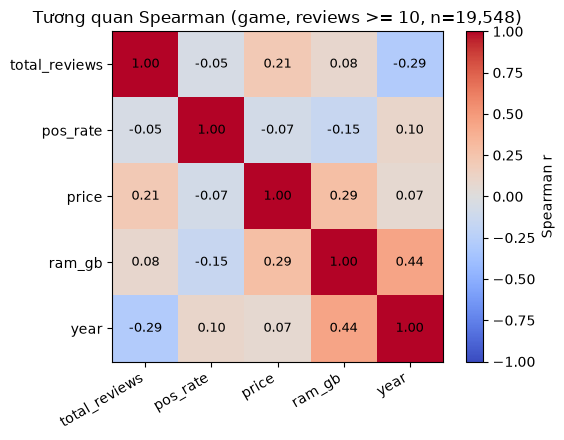

Các cặp biến tương quan mạnh nhất (|r| giảm dần):
ram_gb         year      0.44
price          ram_gb    0.29
total_reviews  year     -0.29
               price     0.21
pos_rate       ram_gb   -0.15


In [9]:
# ==============================================================================
# 7. MỐI QUAN HỆ GIỮA CÁC BIẾN & THỐNG KÊ THEO NHÓM 
# ==============================================================================
g_valid = df[(df["Type"] == "game") & (df["total_reviews"] >= 10)
              & (df["year"].between(MIN_YEAR, CRAWL_DATE.year))].copy()
g_valid["price_tier"] = pd.cut(
    g_valid["price_num"], [-0.01, 0, 5, 10, 20, 1e9],
    labels=["Giá = 0", "≤ $5", "$5–$10", "$10–$20", "> $20"],
)
g_valid["self_published"] = same_company(g_valid["Developers"], g_valid["Publishers"])

print("Bảng 1: Mức đón nhận theo phân khúc giá (game >= 10 reviews)")
display(g_valid.groupby("price_tier", observed=True).agg(
    n_games=("Appid", "size"),
    pos_rate_median=("pos_rate", "median"),
    pos_rate_mean=("pos_rate", "mean"),
    reviews_median=("total_reviews", "median"),
))

print("\nBảng 2: Số game và trung vị review theo năm phát hành (2010 - 2025)")
display(g_valid[g_valid["year"].between(2010, 2025)].groupby(g_valid["year"].astype(int)).agg(
    n_games=("Appid", "size"),
    reviews_median=("total_reviews", "median"),
    pos_rate_median=("pos_rate", "median"),
).T)

print("\nBảng 3: Tự phát hành vs Qua Publisher")
display(g_valid.groupby("self_published").agg(
    n_games=("Appid", "size"),
    price_median=("price_num", "median"),
    reviews_median=("total_reviews", "median"),
    pos_rate_median=("pos_rate", "median"),
))

print("\nCross-tab 1: Phân khúc giá × Tự phát hành (% theo hàng)")
display(pd.crosstab(g_valid["price_tier"], g_valid["self_published"], normalize="index").mul(100).round(1))

print("\nCross-tab 2: Top 10 Genres × mức đón nhận")
gx = (g_valid.dropna(subset=["Genres"])
      .assign(genre=lambda d: d["Genres"].str.split(","))
      .explode("genre"))
gx["genre"] = gx["genre"].str.strip()
top_genres = gx["genre"].value_counts().head(10).index
display(gx[gx["genre"].isin(top_genres)].groupby("genre").agg(
    n_games=("Appid", "size"),
    pos_rate_median=("pos_rate", "median"),
    reviews_median=("total_reviews", "median"),
    price_median=("price_num", "median"),
).sort_values("n_games", ascending=False))

# Ma trận tương quan Spearman
corr_df = pd.DataFrame({
    "total_reviews": g_valid["total_reviews"],
    "pos_rate": g_valid["pos_rate"],
    "price": g_valid["price_num"],
    "ram_gb": g_valid["ram_gb"],
    "year": g_valid["year"],
}).dropna()
corr_mat = corr_df.corr(method="spearman") 

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(corr_mat, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_mat))); ax.set_xticklabels(corr_mat.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr_mat))); ax.set_yticklabels(corr_mat.columns)
for i in range(len(corr_mat)):
    for j in range(len(corr_mat)):
        ax.text(j, i, f"{corr_mat.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, label="Spearman r")
ax.set_title(f"Tương quan Spearman (game, reviews >= 10, n={len(corr_df):,})")
plt.tight_layout()
plt.show()

pairs = corr_mat.where(np.triu(np.ones(corr_mat.shape, dtype=bool), k=1)).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
print("Các cặp biến tương quan mạnh nhất (|r| giảm dần):")
print(pairs.head(5).round(3).to_string())

### 2.9. Tóm tắt khám phá

#### Quan sát chính

1. Sau khi bỏ 142 dòng trùng Appid, còn 29.789 ứng dụng. Game chiếm 75,9% (22.713), DLC 22,0%, nhạc 2,0%, phần còn lại không đáng kể. Số ứng dụng phát hành tăng mạnh theo năm, từ khoảng 150 (2010) lên hơn 5.400 (2025), và 2026 mới có dữ liệu đến 13/06.
2. Lượng review lệch phải rất mạnh. Median là 131 review nhưng mean là 2.351, skew 34. Sau log1p, outlier IQR giảm từ 15,2% xuống 1,2%, nên đuôi dài là dữ liệu thật (Counter-Strike 2 có 1,42 triệu review). `pos_rate` lệch trái (median 0,88, skew −1,62). Giá tập trung ở các mức giá cố định (median 9,99 USD, P99 59,99 USD).
3. Số review median có dạng chữ U theo giá: game miễn phí 540, nhóm ≤ 5 USD chỉ 82, nhóm > 20 USD 650. `pos_rate` median cao nhất ở các nhóm giá thấp và trung bình (0,88–0,89), thấp hơn ở game miễn phí (0,83) và > 20 USD (0,84).
4. Số game (≥ 10 review) tăng từ 126 (2010) lên 3.980 (2025), trong khi review median giảm từ 511 xuống 69. Một phần do game mới chưa có đủ thời gian tích lũy review. RAM yêu cầu median tăng từ khoảng 0,25 GB (2005) lên 4 GB và giữ nguyên từ 2020.
5. Khoảng 55% game tự phát hành, và tỷ lệ này ổn định giữa ba cách định nghĩa (55,1% / 55,3% / 55,5%). Tỷ lệ tự phát hành giảm theo giá, từ 70,8% (miễn phí) xuống 39,5% (> 20 USD). Game tự phát hành rẻ hơn (median 8,99 so với 11,99 USD), ít review hơn (124 so với 198) và `pos_rate` hơi cao hơn (0,89 so với 0,87). Các tương quan Spearman đều yếu (|r| ≤ 0,44, mạnh nhất là `ram_gb`–`year`).

#### Vấn đề chất lượng dữ liệu

- Hai phiên cào được nối vào một file nên `Rank` bị reset. Có 142 Appid trùng, tất cả nằm trong cùng một phiên (chỉ 1 cặp lệch số review).
- Dữ liệu trộn nhiều loại ứng dụng (game, DLC, nhạc, phần cứng). Genres của game còn lẫn nhãn phần mềm (Utilities 169, Design & Illustration 121, Animation & Modeling 97...).
- `price = 0` không đồng nghĩa free-to-play (82% có genre Free To Play, phần còn lại là demo hoặc thiếu `price_overview`).
- Thiếu dữ liệu không ngẫu nhiên mà phụ thuộc Type và năm. Cột cấu hình thiếu 9,8–13,3%, nhưng với game trước 2010 là 38–44%, với nhạc trên 92%, với DLC 20–24%. Publishers thiếu 1.045 dòng, nhưng chỉ 77 dòng là game.
- Các cột cấu hình là chuỗi tự do (OS 4.027, RAM 399, CPU 8.430 chuỗi khác nhau) với lỗi parse như full-width, GHz 220, RAM 2.048 GB. `OsRequirement` thực chất chỉ chứa phiên bản Windows.
- Tên công ty không nhất quán (Developers 14.777 → 14.602 sau chuẩn hóa; Publishers 11.238 → 11.017). Khoảng 11–12% game có nhiều tên developer/publisher trong cùng một ô.
- `Tags` do người dùng gắn sau phát hành, dễ gây data leakage. `ReviewScore` suy ra trực tiếp từ review.

#### Kế hoạch tiền xử lý (Phong viết)

- Bỏ trùng theo Appid (giữ dòng có tổng review lớn hơn). Bỏ `Rank`, `Thumbnails`, và loại `Tags`, `ReviewScore` khỏi mô hình dự đoán.
- Lọc `Type == 'game'`, loại các game gắn nhãn phần mềm. Với bài toán đón nhận, chỉ dùng game có ≥ 10 review (loại 5,6% game không đủ mẫu).
- Parse ngày (khôi phục `April 2026`, loại các dòng không còn ngày hợp lệ), tạo `year` và tuổi game theo mốc 13/06/2026.
- Dùng log1p cho `total_reviews` và `price` khi mô hình hóa hoặc vẽ biểu đồ. Giữ các outlier vì là dữ liệu thật.
- Chuẩn hóa NFKC cho cột cấu hình, parse RAM, GHz, dòng chip và phiên bản Windows. Đặt NaN cho giá trị phi lý (RAM > 128 GB, GHz ngoài [0,5; 6]) sau khi kiểm tra mẫu. Thêm missing indicator cho cột cấu hình và kiểm soát biến năm.
- Chuẩn hóa tên Developer/Publisher, tạo `self_published`, tách cờ `Free To Play` / `Early Access` khỏi Genres, gom nhãn hiếm thành `Other`.

#### Pattern gợi ý câu hỏi

- RAM median tăng từ 0,25 GB (2005) lên 4 GB và bão hòa từ năm 2020. Dữ liệu CPU thiếu chuẩn hóa (chỉ ~46% chứa GHz hoặc dòng Core i). Cả hai cột đều có outlier ảo (RAM 2.048 GB, GHz 220).
- Tự phát hành có review thấp hơn (median 124 vs. 198) nhưng pos_rate cao hơn (0,89 vs. 0,87). Tỷ lệ này giảm mạnh khi giá tăng (70,8% ở game miễn phí xuống 39,5% ở nhóm > 20 USD).
- Số game tăng 6,4 lần (2014–2025) trong khi review median giảm từ 350 xuống 69. Quanh mốc Steam Direct (2017) không có bước nhảy đột ngột ở nhóm ≥ 10 review.
- Chênh lệch pos_rate thô giữa các thể loại khá hẹp (0,81–0,89). 82% game giá 0 USD trùng nhãn Free To Play. Thể loại là nhãn đa trị (multi-label) và nhiều developer phát hành lặp lại.
- Tên nhà phát triển chưa nhất quán và 12,2% game có nhiều developer cùng làm. Nhiều studio chỉ phát hành 1 game duy nhất.
- Nhãn mất cân bằng nặng vì pos_rate lệch trái (median 0,88, lớp dương áp đảo). price và Early Access thực chất là trạng thái tại thời điểm cào, không phải lúc ra mắt.